# Customers Like You: analysis

Runs top to bottom on the files written by `python build_matrix.py`. The model code is in
[recommender.py](recommender.py), so this notebook calls it and explains the results.
Customer IDs are never loaded: customers appear only as row indices (R4).

| Section | Task |
| --- | --- |
| 1 | ML1: the method decision, made before fitting |
| 2 | ML2: choose k, the purchase value and the scoring rule on the validation split |
| 3 | ML3: the recommender ("also bought" lists and customer suggestions) |
| 4 | ML4: hit rate on the held-out test purchases, against best sellers; timing the nightly job |
| 5 | ML5: PCA against Truncated SVD on the same matrix and k (Section 3 of the brief) |
| 6 | ML6: the customer map for marketing |
| 7 | ML7: does the purchase value change the hit rate? |
| 8 | The success targets, checked |

The test purchases (last 2 months) are used only in sections 4, 5 and 7, after every choice has
been made on the validation split (R2).

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

import recommender as rec
from build_matrix import md_table

VALUES = {"log1p": "log(1 + units)", "binary": "1/0 bought", "quantity": "units"}  # saved by build_matrix.py
K_GRID = [10, 20, 30, 50, 70, 100, 150, 200]  # the brief's five values plus 30, 70 and 150
TOLERANCE = 0.01  # 1 point: about one standard error of a validation hit rate
METHODS = {"svd": "Truncated SVD", "pca": "PCA"}
FIGURES, REPORTS = Path("figures"), Path("reports")
FIGURES.mkdir(exist_ok=True)
pct = "{:.1%}".format

In [2]:
# Chart style: validated categorical slots 1-3 (blue, orange, aqua) on the light chart surface
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a"]
COLORS = {"svd": SLOTS[0], "pca": SLOTS[1]}
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})


def k_axis(ax):
    ax.set_xscale("log")
    ax.set_xticks(K_GRID, [str(k) for k in K_GRID])
    ax.minorticks_off()
    ax.set_xlabel("k (components kept)")


def titles(fig, ax, title, subtitle, suptitle=None):
    ax.set_title(title, pad=22)
    ax.text(0, 1.03, subtitle, transform=ax.transAxes, color=INK_2, fontsize=9)
    if suptitle:
        fig.suptitle(suptitle, x=0.01, ha="left", y=1.04, fontsize=13, fontweight="semibold")

## 1. ML1: method decision

Written before anything was fitted: [method_decision.md](method_decision.md). **Truncated SVD is the
main model and PCA is the comparison.** Section 5 checks the decision and its predictions.

## 2. ML2: choose k on the validation split

`build_matrix.py` repeats the train/test split inside the training period: a matrix from purchases
before 9 Aug 2011, and held-out new-product purchases from 9 Aug to 9 Oct 2011
([split_report.md](reports/split_report.md)). Three choices are made here, on validation only:

- **k**, the number of components;
- **the purchase value** in each cell (log(1 + units), 1/0, or raw units; this is also ML7);
- **the scoring rule**: the brief's *cosine* rule, or the *rebuilt row*. The rebuilt row is the same
  sum with dot products, which keeps how much each product sells (section 5 explains why that matters).

**Rule for k, fixed before looking:** take the best purchase value and scoring rule, then the
*smallest* k whose validation hit rate is within 1 point of the best. A smaller k is smaller and
faster, and differences under about one standard error are noise.

In [3]:
validation = {value: rec.load(value, data=rec.DATA / "validation") for value in VALUES}
val_holdout = validation["log1p"][2]
val_customers = np.sort(val_holdout["customer_idx"].unique())


def val_hit_rate(A, score):
    return rec.hit_rate(rec.recommend(A, score, customers=val_customers), val_customers, val_holdout)


rows = []
for value in VALUES:
    A_val = validation[value][0]
    for k in K_GRID:
        model = rec.fit("svd", A_val, k)
        rows.append({"value": value, "k": k, "rule": "rebuilt row",
                     "hit_rate": val_hit_rate(A_val, rec.reconstruction_scorer(model))})
        rows.append({"value": value, "k": k, "rule": "cosine",
                     "hit_rate": val_hit_rate(A_val, rec.similarity_scorer(model.components_.T))})
sweep = pd.DataFrame(rows)
sweep.to_csv(REPORTS / "validation_sweep.csv", index=False)
val_baseline = val_hit_rate(validation["log1p"][0], rec.popularity_scorer(validation["log1p"][0]))
print(f"{len(val_customers):,} validation customers; best-seller baseline {pct(val_baseline)}")
sweep.pivot_table(index="k", columns=["rule", "value"], values="hit_rate").map(pct)

1,397 validation customers; best-seller baseline 25.6%


rule  cosine                 rebuilt row                
value binary  log1p quantity      binary  log1p quantity
k                                                       
10     13.2%  14.7%     6.9%       34.7%  31.8%    18.9%
20     16.8%  18.0%     9.6%       36.8%  34.4%    17.8%
30     19.3%  19.9%    11.7%       39.0%  36.9%    19.7%
50     22.9%  22.0%    10.0%       40.6%  37.3%    20.9%
70     23.6%  21.8%    11.0%       42.4%  38.9%    23.6%
100    23.9%  22.0%    13.7%       41.7%  39.7%    22.6%
150    25.0%  23.1%    12.7%       41.4%  38.2%    25.1%
200    24.8%  20.8%    13.0%       40.6%  35.8%    25.0%

In [4]:
best = sweep.loc[sweep["hit_rate"].idxmax()]
VALUE, RULE = best["value"], best["rule"]
curve = sweep[(sweep["value"] == VALUE) & (sweep["rule"] == RULE)].set_index("k")["hit_rate"]
K = int(curve.index[curve >= curve.max() - TOLERANCE].min())
COSINE_RULE = RULE == "cosine"
choice = {"value": VALUE, "k": K, "rule": RULE, "validation_hit_rate": float(curve[K]),
          "validation_best": {"k": int(curve.idxmax()), "hit_rate": float(curve.max())},
          "validation_baseline": float(val_baseline)}
(REPORTS / "model_choice.json").write_text(json.dumps(choice, indent=2), encoding="utf-8")
print(f"Chosen: {VALUES[VALUE]} matrix, {RULE} rule, k = {K} "
      f"(validation hit rate {pct(curve[K])}; best {pct(curve.max())} at k = {curve.idxmax()})")

Chosen: 1/0 bought matrix, rebuilt row rule, k = 70 (validation hit rate 42.4%; best 42.4% at k = 70)


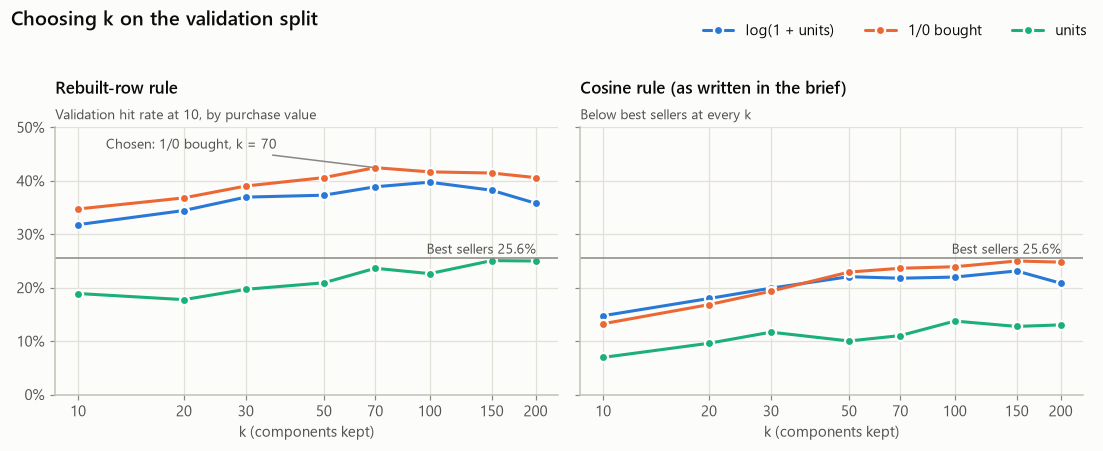

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
for ax, rule in zip(axes, ["rebuilt row", "cosine"]):
    for color, (value, label) in zip(SLOTS, VALUES.items()):
        d = sweep[(sweep["value"] == value) & (sweep["rule"] == rule)]
        ax.plot(d["k"], d["hit_rate"], color=color, marker="o", markersize=6,
                markeredgecolor=SURFACE, markeredgewidth=1.5, label=label)
    ax.axhline(val_baseline, color=MUTED, linewidth=1)
    ax.text(K_GRID[-1], val_baseline + 0.008, f"Best sellers {pct(val_baseline)}", color=INK_2,
            fontsize=9, ha="right")
    k_axis(ax)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylim(0, 0.5)
axes[0].annotate(f"Chosen: {VALUES[VALUE]}, k = {K}", xy=(K, curve[K]), xytext=(12, 0.46), color=INK_2,
                 fontsize=9, arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 1})
titles(fig, axes[0], "Rebuilt-row rule", "Validation hit rate at 10, by purchase value",
       "Choosing k on the validation split")
titles(fig, axes[1], "Cosine rule (as written in the brief)", "Below best sellers at every k")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=3, bbox_to_anchor=(1, 1.04))
fig.tight_layout()
fig.savefig(FIGURES / "choose_k.png")
plt.show()

**What is lost at each k.** ML2 also asks for the reconstruction error against k. It is computed on
the training matrix with the chosen purchase value, for both methods. The two lines are compared in
section 5.

In [6]:
A, products, holdout = rec.load(VALUE)
test_customers = np.sort(holdout["customer_idx"].unique())
buyers = np.diff(A.tocsc().indptr)          # training customers per product
volume = np.asarray(A.sum(axis=1)).ravel()  # each customer's row total
loss = pd.DataFrame([{"k": k, "method": METHODS[m], **rec.compression_loss(rec.fit(m, A, k), A)}
                     for k in K_GRID for m in METHODS])
loss.pivot(index="k", columns="method").round(4)

relative_error               share_kept              
method            PCA Truncated SVD        PCA Truncated SVD
k                                                           
10             0.8976        0.8980     0.1545        0.1936
20             0.8755        0.8757     0.1957        0.2331
30             0.8586        0.8588     0.2263        0.2624
50             0.8315        0.8317     0.2744        0.3083
70             0.8090        0.8091     0.3132        0.3454
100            0.7797        0.7798     0.3621        0.3919
150            0.7374        0.7375     0.4293        0.4560
200            0.7003        0.7004     0.4853        0.5094

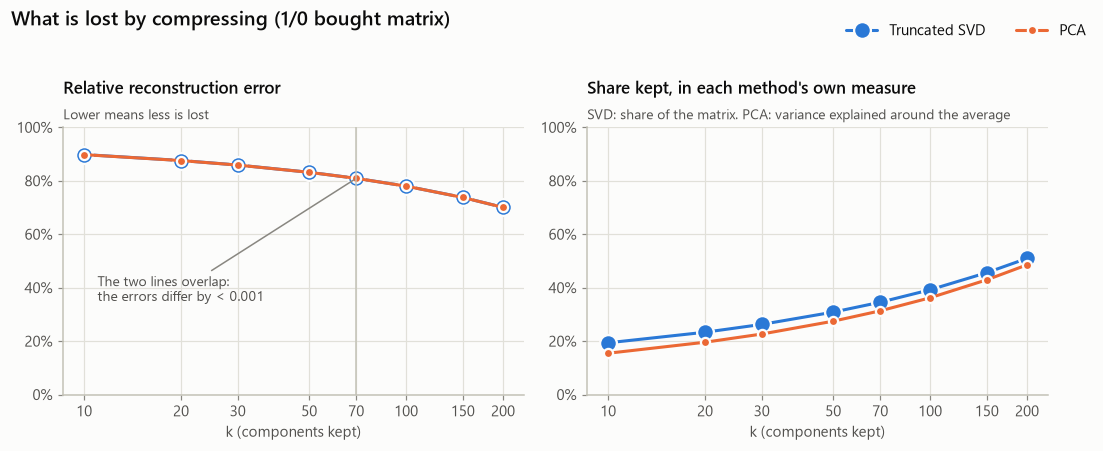

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharex=True)
panels = [("relative_error", "Relative reconstruction error", "Lower means less is lost"),
          ("share_kept", "Share kept, in each method's own measure",
           "SVD: share of the matrix. PCA: variance explained around the average")]
for ax, (column, title, subtitle) in zip(axes, panels):
    for m, name in METHODS.items():  # SVD drawn larger underneath, so it shows where the lines overlap
        d = loss[loss["method"] == name]
        ax.plot(d["k"], d[column], color=COLORS[m], marker="o", markersize=11 if m == "svd" else 6,
                markeredgecolor=SURFACE, markeredgewidth=1.5, label=name)
    titles(fig, ax, title, subtitle)
    k_axis(ax)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylim(0, 1)
axes[0].axvline(K, color=AXIS, linewidth=1)
axes[0].annotate("The two lines overlap:\nthe errors differ by < 0.001",
                 xy=(K, loss.query("k == @K")["relative_error"].mean()), xytext=(11, 0.35), color=INK_2,
                 fontsize=9, arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 1})
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, bbox_to_anchor=(1, 1.04))
fig.suptitle(f"What is lost by compressing ({VALUES[VALUE]} matrix)", x=0.01, ha="left", y=1.04,
             fontsize=13, fontweight="semibold")
fig.tight_layout()
fig.savefig(FIGURES / "compression_loss.png")
plt.show()

The error falls smoothly with k and has no elbow, so it cannot pick k on its own. Validation hit
rate is the measure Sarah cares about, so it decides k. Every k in the grid stores less than a tenth
of the full table (success target 1).

## 3. ML3: the recommender

The final model is fitted on the full training matrix. The "customers who bought this also bought"
box for product *j* uses the same scoring rule as the customer suggestions. It shows what the model
would recommend to someone who has just bought *j*. The lists for the two best sellers are shown
next to the brief's cosine rule.

In [8]:
svd, svd_seconds, svd_peak = rec.measure(lambda: rec.fit("svd", A, K))
scorer = rec.similarity_scorer(svd.components_.T) if COSINE_RULE else rec.reconstruction_scorer(svd)
also_bought = rec.similar_products(svd.components_.T, cosine=COSINE_RULE)
cosine_lists = rec.similar_products(svd.components_.T, cosine=True)
for j in np.argsort(-buyers)[:2]:
    display(Markdown(f"**Customers who bought {products['Description'].iloc[j].title()} also bought...**"),
            pd.DataFrame({f"{RULE} rule (chosen)": products["Description"].iloc[also_bought[j]].str.title().to_numpy(),
                          "cosine rule": products["Description"].iloc[cosine_lists[j]].str.title().to_numpy()},
                         index=pd.RangeIndex(1, 11, name="rank")))

**Customers who bought White Hanging Heart T-Light Holder also bought...**

,rebuilt row rule (chosen),cosine rule
rank,,
1,Red Hanging Heart T-Light Holder,Red Hanging Heart T-Light Holder
2,Candleholder Pink Hanging Heart,Candleholder Pink Hanging Heart
3,Zinc Metal Heart Decoration,White Metal Lantern
4,Cream Heart Card Holder,Colour Glass. Star T-Light Holder
5,Natural Slate Heart Chalkboard,Cream Heart Card Holder
6,Colour Glass. Star T-Light Holder,White Lovebird Lantern
7,Hanging Metal Heart Lantern,Red Hanging Metal Star Tlight Hldr
8,White Metal Lantern,Glass Star Frosted T-Light Holder
9,Rex Cash+Carry Jumbo Shopper,Jasmine Tea Incense In Tin


**Customers who bought Regency Cakestand 3 Tier also bought...**

,rebuilt row rule (chosen),cosine rule
rank,,
1,Roses Regency Teacup And Saucer,Roses Regency Teacup And Saucer
2,Green Regency Teacup And Saucer,Green Regency Teacup And Saucer
3,Pink Regency Teacup And Saucer,Pink Regency Teacup And Saucer
4,Red Retrospot Cake Stand,Silver Oval Shape Trinket Box
5,Assorted Colour Bird Ornament,Kensington Coffee Set
6,Set Of 3 Regency Cake Tins,Cake Stand 3 Tier Magic Garden
7,Sweetheart Cakestand 3 Tier,Cake Stand Lovebird 2 Tier White
8,White Wood Garden Plant Ladder,Red Retrospot Cake Stand
9,Natural Slate Heart Chalkboard,Black And White Paisley Flower Mug


## 4. ML4: evaluation on the held-out test purchases

Hit rate at 10 is the share of test customers with at least one held-out purchase in their top 10.
A held-out purchase is a product bought in the last 2 months that the customer had never bought
before. Products already in a customer's history are never recommended. The baseline recommends the
10 products with the most training buyers that the customer has not bought (R3). The 95% interval
for the difference resamples customers (2,000 bootstrap samples, seed 42).

In [9]:
def test_hits(score):
    return rec.customer_hits(rec.recommend(A, score, customers=test_customers), test_customers, holdout)


model_hits, base_hits = test_hits(scorer), test_hits(rec.popularity_scorer(A))
cosine_hits = test_hits(rec.similarity_scorer(svd.components_.T))
low, high = rec.bootstrap_difference(model_hits, base_hits)
gain = model_hits.mean() - base_hits.mean()
results = pd.DataFrame({"hit rate at 10": [pct(model_hits.mean()), pct(base_hits.mean()), pct(cosine_hits.mean())]},
                       index=[f"model: SVD, {VALUES[VALUE]}, k = {K}, {RULE} rule", "best-seller baseline",
                              "for reference: the brief's cosine rule, same model"])
print(f"{len(test_customers):,} test customers. Model minus baseline: {gain * 100:+.1f} points "
      f"(95% interval {low * 100:+.1f} to {high * 100:+.1f})")
results

1,903 test customers. Model minus baseline: +13.5 points (95% interval +10.9 to +16.1)


,hit rate at 10
"model: SVD, 1/0 bought, k = 70, rebuilt row rule",40.4%
best-seller baseline,26.9%
"for reference: the brief's cosine rule, same model",24.5%


**What the suggestions look like across the catalogue.** A model that keeps popularity can drift
towards the same few products for everyone, so we check how many different products it actually
suggests.

In [10]:
top_all = rec.recommend(A, scorer)
best_ten = set(np.argsort(-buyers)[:10])
coverage = {"products suggested to at least one customer": f"{len(np.unique(top_all)):,} of {A.shape[1]:,}",
            "share of all suggestion slots taken by the 10 best sellers": pct(np.isin(top_all, list(best_ten)).mean()),
            "customers whose top 10 is exactly the best-seller list": pct(
                np.mean([set(row) == set(b) for row, b in zip(top_all, rec.recommend(A, rec.popularity_scorer(A)))]))}
pd.Series(coverage)

products suggested to at least one customer                   1,083 of 3,680
share of all suggestion slots taken by the 10 best sellers              5.9%
customers whose top 10 is exactly the best-seller list                  0.0%
dtype: str

**Timing the nightly job.** The whole job: fit, an "also bought" list for every product, and a top 10
for every customer. Best of 3 runs; peak memory is what the job allocates (`tracemalloc`).
`python nightly_job.py` runs the same job and writes the lists to `data/output/`.

In [11]:
_, job_seconds, job_peak = rec.measure(lambda: rec.nightly_job(A, K, cosine=COSINE_RULE))
factors_mb = rec.factor_size_mb(svd, A)
dense_mb = A.shape[0] * A.shape[1] * 8 / rec.MB
pd.Series({"nightly job (seconds)": f"{job_seconds:.2f}", "peak memory (MB)": f"{job_peak:.0f}",
           "stored factors (MB)": f"{factors_mb:.1f}", "full customer x product table (MB)": f"{dense_mb:.1f}",
           "compression": f"{dense_mb / factors_mb:.0f}x smaller"})

nightly job (seconds)                        0.66
peak memory (MB)                              327
stored factors (MB)                           5.1
full customer x product table (MB)          160.6
compression                           31x smaller
dtype: str

## 5. ML5: PCA or SVD? (Section 3 of the brief)

PCA is run on the same matrix with the same k as the chosen SVD model. Both use the ARPACK solver
and seed 42, so any difference comes from centring alone. PCA runs on the sparse matrix with
scikit-learn's implicit centring. Times are the best of 3 runs. Peak memory is what the fit
allocates, not counting the input matrix. The randomized solver, scikit-learn's default for SVD, is
shown for reference.

In [12]:
models = {"svd": svd}
models["pca"], pca_seconds, pca_peak = rec.measure(lambda: rec.fit("pca", A, K))
randomized, rand_seconds, rand_peak = rec.measure(
    lambda: TruncatedSVD(n_components=K, algorithm="randomized", random_state=rec.SEED).fit(A))
cost = {name: {"fit seconds": s, "peak MB during fit": p, "stored factors MB": rec.factor_size_mb(mdl, A)}
        for name, mdl, s, p in [("Truncated SVD", svd, svd_seconds, svd_peak), ("PCA", models["pca"], pca_seconds, pca_peak),
                                ("Truncated SVD, randomized solver", randomized, rand_seconds, rand_peak)]}
print(f"Relative reconstruction error at k = {K}: ARPACK {rec.compression_loss(svd, A)['relative_error']:.4f}, "
      f"randomized {rec.compression_loss(randomized, A)['relative_error']:.4f}")
pd.DataFrame(cost).T.round(2)

Relative reconstruction error at k = 70: ARPACK 0.8091, randomized 0.8100


,fit seconds,peak MB during fit,stored factors MB
Truncated SVD,0.29,15.65,5.12
PCA,0.27,10.75,5.15
"Truncated SVD, randomized solver",0.53,12.91,5.12


**What centring costs.** PCA subtracts each product's average from its column. Every kept product
has at least 10 buyers, so every average is above zero and every zero cell becomes a small negative
number. Implicit centring avoids storing that matrix. Centring it ourselves, which is what PCA means
on paper, costs this much:

In [13]:
mean = models["pca"].mean_
n_cells = A.shape[0] * A.shape[1]
print(f"Product averages: mean {mean.mean():.4f}, largest {mean.max():.4f}; all positive: {(mean > 0).all()}")
print(f"Before centring {A.nnz / n_cells:.2%} of the {n_cells:,} cells are non-zero; after centring none are "
      f"zero, which is {dense_mb:.1f} MB stored densely")
_, dense_seconds, dense_peak = rec.measure(
    lambda: PCA(n_components=K, svd_solver="arpack", random_state=rec.SEED).fit(A.toarray()), repeats=1)
print(f"PCA on the explicitly centred dense matrix: {dense_seconds:.2f} s, peak {dense_peak:.0f} MB")

Product averages: mean 0.0205, largest 0.2595; all positive: True
Before centring 2.05% of the 20,078,080 cells are non-zero; after centring none are zero, which is 160.6 MB stored densely


PCA on the explicitly centred dense matrix: 2.02 s, peak 493 MB


**Why centring changes so little here.** In the section 2 table, the reconstruction error of both
methods agrees to three decimals, while "share kept" differs, because PCA divides by a total that
leaves out the average customer. The cell below measures how big that average is.

In [14]:
pca_check = loss.query("k == @K and method == 'PCA'")["share_kept"].item()
assert np.isclose(pca_check, models["pca"].explained_variance_ratio_.sum())  # share kept = explained variance ratio
average_share = A.shape[0] * mean @ mean / sp.linalg.norm(A) ** 2
align = np.abs(np.sum(svd.components_ * models["pca"].components_, axis=1))
subspace = np.linalg.svd(svd.components_ @ models["pca"].components_.T, compute_uv=False).min()
print(f"The average customer is {average_share:.1%} of the matrix (share of ||A||^2)")
print(f"Cosine between SVD component 1 and the average customer: "
      f"{abs(svd.components_[0] @ mean) / np.linalg.norm(mean):.3f}")
print(f"|cosine| between the methods, components 1-5: {np.round(align[:5], 3)}")
print(f"Smallest cosine between the two {K}-dimensional subspaces: {subspace:.3f}")

The average customer is 4.7% of the matrix (share of ||A||^2)
Cosine between SVD component 1 and the average customer: 0.990
|cosine| between the methods, components 1-5: [0.995 0.999 1.    0.993 0.962]
Smallest cosine between the two 70-dimensional subspaces: 0.968


The matrix is 98% zeros, so the average customer buys almost nothing of any one product. The
averages PCA removes are tiny, and SVD's first component already points almost exactly along them.
The directions both methods find are the same, component by component and as a whole subspace.

**What component 1 represents.** A component's sign is arbitrary, so each is flipped to point
towards "buys more".

In [15]:
comp1 = {}
for m, model in models.items():
    sign = np.sign(model.components_[0].sum())
    weights = model.components_[0] * sign
    scores = model.transform(A)[:, 0] * sign
    comp1[m] = {"weights": weights, "positive": (weights > 0).mean(),
                "r_popularity": np.corrcoef(weights, buyers)[0, 1], "r_volume": np.corrcoef(scores, volume)[0, 1]}
pd.DataFrame({METHODS[m]: {"products with a positive weight": f"{c['positive']:.1%}",
                           "correlation of product weight with its number of buyers": f"{c['r_popularity']:.2f}",
                           "correlation of customer score with their row total": f"{c['r_volume']:.2f}"}
              for m, c in comp1.items()})

,Truncated SVD,PCA
products with a positive weight,100.0%,100.0%
correlation of product weight with its number of buyers,0.99,0.95
correlation of customer score with their row total,0.98,0.98


In [16]:
def ends(weights, n=6):
    order = np.argsort(-weights)
    return pd.DataFrame({"highest weight": products["Description"].iloc[order[:n]].str.title().to_numpy(),
                         "lowest weight": products["Description"].iloc[order[::-1][:n]].str.title().to_numpy()},
                        index=pd.RangeIndex(1, n + 1, name="rank"))


for label, weights in [("SVD component 1", comp1["svd"]["weights"]), ("PCA component 1", comp1["pca"]["weights"]),
                       ("PCA component 2", models["pca"].components_[1])]:
    display(Markdown(f"**{label}**"), ends(weights))

**SVD component 1**

,highest weight,lowest weight
rank,,
1,White Hanging Heart T-Light Holder,Amber Glass Tassle Bag Charm
2,Pack Of 72 Retro Spot Cake Cases,Purple Glass Tassle Bag Charm
3,Regency Cakestand 3 Tier,Four Picture White Glass Frame
4,Lunch Bag Red Retrospot,Pink Square Compact Mirror
5,Jumbo Bag Red Retrospot,Frosted White Base
6,60 Teatime Fairy Cake Cases,Jazz Hearts Spiral Notepad


**PCA component 1**

,highest weight,lowest weight
rank,,
1,Pack Of 72 Retro Spot Cake Cases,Next Day Carriage
2,Lunch Bag Red Retrospot,Amber Glass Tassle Bag Charm
3,White Hanging Heart T-Light Holder,Cherry Blossom Bathroom Cabinet
4,Lunch Bag Spaceboy Design,Frosted White Base
5,Jumbo Bag Red Retrospot,Purple Glass Tassle Bag Charm
6,60 Teatime Fairy Cake Cases,Jazz Hearts Spiral Notepad


**PCA component 2**

,highest weight,lowest weight
rank,,
1,White Hanging Heart T-Light Holder,Lunch Bag Spaceboy Design
2,Heart Of Wicker Small,Plasters In Tin Spaceboy
3,Heart Of Wicker Large,Spaceboy Lunch Box
4,Love Building Block Word,Round Snack Boxes Set Of4 Woodland
5,Wooden Frame Antique White,Lunch Bag Woodland
6,Wooden Picture Frame White Finish,Plasters In Tin Circus Parade


**Component 1 is overall buying in both methods.** All, or nearly all, products weigh in with the
same sign. The heaviest weights go to the best sellers and the lightest to rarely bought items. A
customer's score follows how much they buy. PCA removes the average customer, but not the
differences in *how much* customers buy, and those differences are still the biggest variation. The
first contrast between kinds of shops is **component 2** in both methods: home decoration (hanging
hearts, wicker hearts, frames) against children's lunch and party items (Spaceboy and Woodland
lunch bags, plasters in tins).

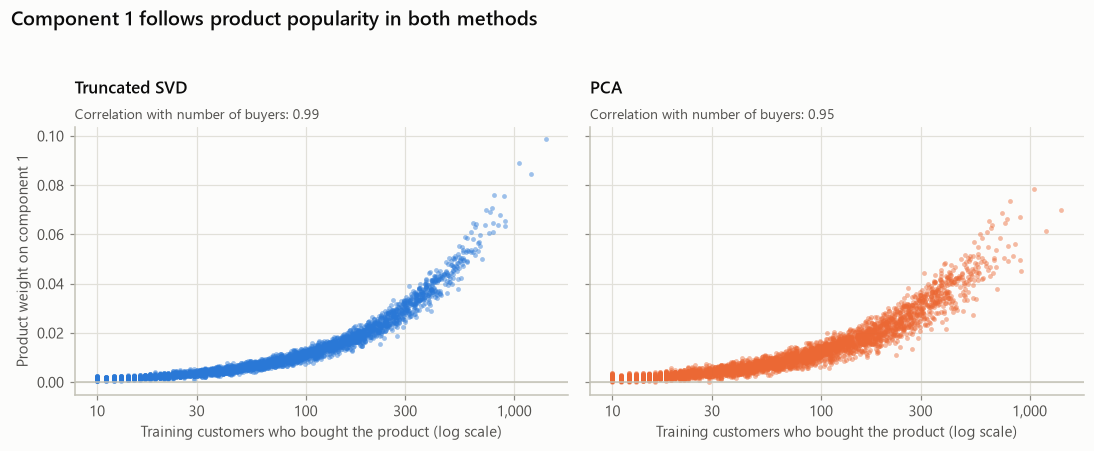

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
for ax, (m, name) in zip(axes, METHODS.items()):
    ax.scatter(buyers, comp1[m]["weights"], s=10, color=COLORS[m], alpha=0.45, linewidths=0)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.set_xscale("log")
    ax.set_xticks([10, 30, 100, 300, 1000], ["10", "30", "100", "300", "1,000"])
    ax.minorticks_off()
    titles(fig, ax, name, f"Correlation with number of buyers: {comp1[m]['r_popularity']:.2f}")
    ax.set_xlabel("Training customers who bought the product (log scale)")
axes[0].set_ylabel("Product weight on component 1")
fig.suptitle("Component 1 follows product popularity in both methods", x=0.01, ha="left", y=1.04,
             fontsize=13, fontweight="semibold")
fig.tight_layout()
fig.savefig(FIGURES / "component1_popularity.png")
plt.show()

**What it means for recommendations.** The "also bought" lists of the two methods, and their hit
rates on the test purchases under both scoring rules.

In [18]:
similar = {m: rec.similar_products(model.components_.T, cosine=COSINE_RULE) for m, model in models.items()}
overlap = np.mean([len(set(a) & set(b)) for a, b in zip(similar["svd"], similar["pca"])]) / 10
print(f"Across all {A.shape[1]:,} products, the SVD and PCA 'also bought' lists share {overlap:.0%} of their products")

COSINE, REBUILT = "cosine similarity (brief's ML3)", "rebuilt row (dot products)"
baseline = base_hits.mean()
hits = pd.DataFrame({METHODS[m]: {COSINE: test_hits(rec.similarity_scorer(model.components_.T)).mean(),
                                  REBUILT: test_hits(rec.reconstruction_scorer(model)).mean(),
                                  "best-seller baseline": baseline}
                     for m, model in models.items()})
hits.map(pct)

Across all 3,680 products, the SVD and PCA 'also bought' lists share 96% of their products


,Truncated SVD,PCA
cosine similarity (brief's ML3),24.5%,24.9%
rebuilt row (dot products),40.4%,40.6%
best-seller baseline,26.9%,26.9%


**Why cosine loses to best sellers.** Normalising every product vector to length 1 throws away how
strongly a product is bought, and that is exactly the signal best sellers use. The rebuilt row keeps
it. For PCA the rebuilt row is the average customer plus that customer's deviations. Splitting the
two shows what the removed average is worth:

In [19]:
V = models["pca"].components_.T
average_effect = pd.Series({
    "PCA rebuilt row (average + deviations)": hits.loc[REBUILT, "PCA"],
    "deviations only (average dropped)": test_hits(lambda rows: (rows @ V - mean @ V) @ V.T).mean(),
    "average customer only": test_hits(lambda rows: np.tile(mean, (rows.shape[0], 1))).mean(),
})
average_effect.map(pct)

PCA rebuilt row (average + deviations)    40.6%
deviations only (average dropped)         39.2%
average customer only                     26.9%
dtype: str

In [20]:
score_seconds = {}
for m, model in models.items():
    score = rec.similarity_scorer(model.components_.T) if COSINE_RULE else rec.reconstruction_scorer(model)
    _, score_seconds[m], _ = rec.measure(lambda: rec.recommend(A, score), repeats=1)
    print(f"{METHODS[m]}: top 10 for all {A.shape[0]:,} customers in {score_seconds[m]:.2f} s")

Truncated SVD: top 10 for all 5,456 customers in 0.31 s


PCA: top 10 for all 5,456 customers in 0.29 s


**The ML5 table and the ML1 predictions.** The cell below fills in the brief's table, checks every
ML1 prediction against the numbers, and writes both to [reports/pca_vs_svd.md](reports/pca_vs_svd.md).

In [21]:
svd_loss, pca_loss = rec.compression_loss(svd, A), rec.compression_loss(models["pca"], A)
c_svd, c_pca, h = cost["Truncated SVD"], cost["PCA"], hits
expected_mb = (A.shape[0] + A.shape[1]) * K * 8 / rec.MB
table = pd.DataFrame([
    ("Matrix and k used", f"{VALUES[VALUE]}, k = {K}", f"{VALUES[VALUE]}, k = {K}"),
    ("Fit time (seconds)", f"{c_pca['fit seconds']:.2f}", f"{c_svd['fit seconds']:.2f}"),
    ("Peak memory during fit (MB)",
     f"{c_pca['peak MB during fit']:.1f} with implicit centring; {dense_peak:.0f} if centred explicitly",
     f"{c_svd['peak MB during fit']:.1f}"),
    ("Size of stored factors (MB)", f"{c_pca['stored factors MB']:.2f} (factors + {A.shape[1]:,} product averages)",
     f"{c_svd['stored factors MB']:.2f}"),
    ("Variance explained or relative reconstruction error",
     f"{pct(pca_loss['share_kept'])} of variance explained; relative error {pca_loss['relative_error']:.3f}",
     f"Relative error {svd_loss['relative_error']:.3f} (keeps {pct(svd_loss['share_kept'])} of the matrix)"),
    ("Hit rate at 10 on held-out purchases",
     f"{pct(h.loc[REBUILT, 'PCA'])} rebuilt row; {pct(h.loc[COSINE, 'PCA'])} cosine",
     f"{pct(h.loc[REBUILT, 'Truncated SVD'])} rebuilt row; {pct(h.loc[COSINE, 'Truncated SVD'])} cosine"),
    ("Best-seller baseline hit rate at 10", pct(baseline), pct(baseline)),
    ("What component 1 represents, in words",
     f"Also overall buying, measured from the average customer: {comp1['pca']['positive']:.1%} of products "
     f"weigh positively (correlation with buyers {comp1['pca']['r_popularity']:.2f}). The first contrast between "
     "kinds of shops is component 2: home decoration against children's lunch and party items.",
     f"Overall buying: every product weighs positively, more for popular products (correlation with buyers "
     f"{comp1['svd']['r_popularity']:.2f}); a customer's score follows how much they buy "
     f"(correlation {comp1['svd']['r_volume']:.2f})."),
    (f"Top 10 for all {A.shape[0]:,} customers (seconds)", f"{score_seconds['pca']:.2f}", f"{score_seconds['svd']:.2f}"),
], columns=["Measure", "PCA", "Truncated SVD"])

held = lambda ok: "Held" if ok else "Wrong"
lead = max(h.loc[s, "PCA"] - h.loc[s, "Truncated SVD"] for s in (COSINE, REBUILT))
beats = lambda s: h.loc[s].min() > baseline
predictions = pd.DataFrame([
    ("SVD fits at least as fast as PCA and needs less memory",
     f"{c_svd['fit seconds']:.2f} s vs {c_pca['fit seconds']:.2f} s; "
     f"{c_svd['peak MB during fit']:.1f} MB vs {c_pca['peak MB during fit']:.1f} MB",
     held(c_svd["fit seconds"] <= 1.1 * c_pca["fit seconds"] and c_svd["peak MB during fit"] < c_pca["peak MB during fit"])),
    ("Centring explicitly needs at least 160 MB", f"Peak {dense_peak:.0f} MB", held(dense_peak >= 160)),
    ("SVD component 1: one sign for every product, follows popularity",
     f"{comp1['svd']['positive']:.0%} positive; correlation {comp1['svd']['r_popularity']:.2f}",
     held(comp1["svd"]["positive"] == 1 and comp1["svd"]["r_popularity"] > 0.8)),
    ("PCA component 1: mixed signs, a contrast between two groups",
     f"{comp1['pca']['positive']:.1%} positive; correlation {comp1['pca']['r_popularity']:.2f}",
     held(comp1["pca"]["positive"] < 0.9)),
    ("Stored factors about the same size for both: (customers + products) x k x 8 bytes",
     f"{c_svd['stored factors MB']:.2f} MB vs {c_pca['stored factors MB']:.2f} MB (expected {expected_mb:.2f})",
     held(all(abs(c["stored factors MB"] / expected_mb - 1) < 0.02 for c in (c_svd, c_pca)))),
    ("SVD's hit rate at least as high as PCA's",
     f"Rebuilt row {pct(h.loc[REBUILT, 'Truncated SVD'])} vs {pct(h.loc[REBUILT, 'PCA'])}; cosine "
     f"{pct(h.loc[COSINE, 'Truncated SVD'])} vs {pct(h.loc[COSINE, 'PCA'])}",
     f"Rebuilt row: {held(h.loc[REBUILT, 'Truncated SVD'] >= h.loc[REBUILT, 'PCA'])}; "
     f"cosine: {held(h.loc[COSINE, 'Truncated SVD'] >= h.loc[COSINE, 'PCA'])}"),
    ("Both methods beat the best-seller baseline", f"Baseline {pct(baseline)}",
     f"Rebuilt row: {held(beats(REBUILT))}; cosine: {held(beats(COSINE))}"),
    ("Decision rule: switch to PCA if its hit rate is at least 1 point higher",
     f"PCA's largest lead: {lead * 100:+.1f} points",
     "Switch to PCA" if lead >= 0.01 else "Decision stands: Truncated SVD"),
], columns=["ML1 prediction", "Result", "Verdict"])
display(table, predictions)

,Measure,PCA,Truncated SVD
0,Matrix and k used,"1/0 bought, k = 70","1/0 bought, k = 70"
1,Fit time (seconds),0.27,0.29
2,Peak memory during fit (MB),10.8 with implicit centring; 493 if centred ex...,15.6
3,Size of stored factors (MB),"5.15 (factors + 3,680 product averages)",5.12
4,Variance explained or relative reconstruction ...,31.3% of variance explained; relative error 0.809,Relative error 0.809 (keeps 34.5% of the matrix)
5,Hit rate at 10 on held-out purchases,40.6% rebuilt row; 24.9% cosine,40.4% rebuilt row; 24.5% cosine
6,Best-seller baseline hit rate at 10,26.9%,26.9%
7,"What component 1 represents, in words","Also overall buying, measured from the average...",Overall buying: every product weighs positivel...
8,"Top 10 for all 5,456 customers (seconds)",0.29,0.31


,ML1 prediction,Result,Verdict
0,SVD fits at least as fast as PCA and needs les...,0.29 s vs 0.27 s; 15.6 MB vs 10.8 MB,Wrong
1,Centring explicitly needs at least 160 MB,Peak 493 MB,Held
2,"SVD component 1: one sign for every product, f...",100% positive; correlation 0.99,Held
3,"PCA component 1: mixed signs, a contrast betwe...",100.0% positive; correlation 0.95,Wrong
4,Stored factors about the same size for both: (...,5.12 MB vs 5.15 MB (expected 5.12),Held
5,SVD's hit rate at least as high as PCA's,Rebuilt row 40.4% vs 40.6%; cosine 24.5% vs 24.9%,Rebuilt row: Wrong; cosine: Wrong
6,Both methods beat the best-seller baseline,Baseline 26.9%,Rebuilt row: Held; cosine: Wrong
7,Decision rule: switch to PCA if its hit rate i...,PCA's largest lead: +0.3 points,Decision stands: Truncated SVD


In [22]:
report = f'''# PCA vs Truncated SVD (ML5)

Generated by `analysis.ipynb` (section 5). Both methods were fitted on the training matrix with the
purchase value and k chosen on the validation split ({VALUES[VALUE]}, {A.shape[0]:,} customers x
{A.shape[1]:,} products, k = {K}), with the same ARPACK solver and seed {rec.SEED}. The decision being
tested was written before fitting: [method_decision.md](../method_decision.md). A first run at
k = 50 on the log(1 + units) matrix, before k and the purchase value were chosen, gave the same
conclusions.

## Comparison table

{md_table(table)}

Fit time is the best of 3 runs. Peak memory is what the fit allocates (`tracemalloc`), not counting
the input matrix. Hit rate at 10 is the share of the {len(test_customers):,} test customers with at
least one held-out purchase in their top 10. "Cosine" is the brief's ML3 rule; "rebuilt row" scores
with the customer's row of A_k (dot products instead of cosines), the rule chosen on validation.

## What our numbers show

1. **On this matrix, PCA and SVD give practically the same model.** The average customer that PCA
   removes is only {average_share:.1%} of the matrix: centring shifts every zero by
   {mean.mean():.3f} on average. The reconstruction errors agree to three decimals
   ({svd_loss["relative_error"]:.3f} vs {pca_loss["relative_error"]:.3f}). The first five components
   point the same way (cosine at least {align[:5].min():.3f}), and the two {K}-dimensional subspaces
   agree to {subspace:.3f}. The "also bought" lists share {overlap:.0%} of their products.
2. **The headline numbers differ only because they divide by different totals.** "Keeps
   {pct(svd_loss["share_kept"])} of the matrix" (SVD) and "explains {pct(pca_loss["share_kept"])} of the
   variance" (PCA) describe the same fit. PCA's total leaves out the average customer.
3. **Centring is costly only if it is done by hand.** scikit-learn's implicit centring keeps PCA as
   cheap as SVD ({c_pca["fit seconds"]:.2f} s against {c_svd["fit seconds"]:.2f} s). Centring the
   matrix explicitly makes all {n_cells:,} cells non-zero and pushes peak memory to {dense_peak:.0f} MB.
4. **Component 1 is overall buying in both methods.** Removing the average does not remove the
   differences in how much customers buy, and those are the biggest variation. The first contrast
   between kinds of shops (home decoration against children's lunch and party items) is component 2
   in both.
5. **Centring matters for the scoring rule, not the method.** The brief's cosine rule normalises each
   product vector to length 1, which throws away how much a product sells. That leaves both methods
   below the baseline ({pct(h.loc[COSINE, "Truncated SVD"])} SVD, {pct(h.loc[COSINE, "PCA"])} PCA, against
   {pct(baseline)}). The rebuilt row keeps that signal: {pct(h.loc[REBUILT, "Truncated SVD"])} (SVD) and
   {pct(h.loc[REBUILT, "PCA"])} (PCA). Without its average, PCA's rebuilt row drops to
   {pct(average_effect.iloc[1])}: the average customer is worth
   {(h.loc[REBUILT, "PCA"] - average_effect.iloc[1]) * 100:.1f} points.
6. **Decision: {"Truncated SVD stays" if lead < 0.01 else "switch to PCA"}.** By the rule written in ML1,
   PCA's largest lead is {lead * 100:+.1f} points{", under the 1-point bar" if lead < 0.01 else ""}. SVD
   works on the sparse matrix as it is, needs no averages stored, and its error is the "what we lose"
   number for the memo.

## ML1 predictions against the results

{md_table(predictions)}

## Figures

![What is lost by compressing](../figures/compression_loss.png)

![Component 1 against product popularity](../figures/component1_popularity.png)
'''
(REPORTS / "pca_vs_svd.md").write_text(report, encoding="utf-8")
print(f"wrote {REPORTS / 'pca_vs_svd.md'}")

wrote reports\pca_vs_svd.md


## 6. ML6: the customer map

Component 1 is overall buying (section 5). Plotting components 1 and 2 as they are would therefore
mostly sort shops by size, and a big home-decor shop would sit far from a small one. The map uses
the same two components with two changes, so that its axes read as **how much** and **what**:

- **x = component 1** on a log scale: how broadly the customer buys;
- **y = component 2 divided by component 1**: the customer's taste, from children's lunch and party
  items (low) to home decoration (high), whatever their size.

Customers are clustered on these two standardised coordinates with k-means (10 restarts, seed 42),
for 3 to 6 groups. Each group is described by its **distinctive products**: among the 50 products the
group buys most, the 10 with the highest *lift*, which is how many times more often the group buys them
than the average customer. Success target 4 needs every group to hold at least 5% of customers and no
two groups to share more than 5 of their top-10 distinctive products.

In [23]:
customers = pd.read_csv(rec.DATA / "customer_index.csv",  # Customer ID is not read (R4)
                        usecols=["customer_idx", "Country", "n_products", "n_invoices", "spend_gbp"])
anchor = int(products.index[products["StockCode"] == "85123A"][0])  # white hanging heart: orients component 2
Z = A @ svd.components_.T                                           # customer scores, U S
size = Z[:, 0] * np.sign(svd.components_[0].sum())
taste = Z[:, 1] * np.sign(svd.components_[1, anchor]) / size
X = StandardScaler().fit_transform(np.c_[np.log(size), taste])

bought = (A > 0).astype(float)
share_all = np.asarray(bought.mean(axis=0)).ravel()


def distinctive(labels, g, n=10, pool=50):
    share = np.asarray(bought[labels == g].mean(axis=0)).ravel()
    candidates = np.argsort(-share)[:pool]  # products the group really buys
    return candidates[np.argsort(-(share[candidates] / share_all[candidates]), kind="stable")][:n]


def names(idx):
    # Product names for display, without repeats such as the A-to-Z letter variants of one item
    seen, out = set(), []
    for name in products["Description"].iloc[idx].str.title():
        key = re.sub(r'"[^"]*"', "", name).strip()
        if key not in seen:
            seen.add(key)
            out.append(name)
    return out


def quality(labels):
    tops = [set(distinctive(labels, g)) for g in np.unique(labels)]
    return {"silhouette": silhouette_score(X, labels, sample_size=3000, random_state=rec.SEED),
            "smallest group": np.bincount(labels).min() / len(labels),
            "most shared top-10 products": max(len(a & b) for i, a in enumerate(tops) for b in tops[i + 1:])}


solutions = {g: rec.kmeans(X, g) for g in range(3, 7)}
options = pd.DataFrame({g: quality(labels) for g, labels in solutions.items()}).T.rename_axis("groups")
options["meets target 4"] = (options["smallest group"] >= 0.05) & (options["most shared top-10 products"] <= 5)
N_GROUPS = int(options[options["meets target 4"]]["silhouette"].idxmax())
labels = solutions[N_GROUPS]
print(f"Chosen: {N_GROUPS} groups (highest silhouette among the options that meet target 4)")
options.style.format({"silhouette": "{:.3f}", "smallest group": "{:.1%}", "most shared top-10 products": "{:.0f}"})

Chosen: 4 groups (highest silhouette among the options that meet target 4)


,silhouette,smallest group,most shared top-10 products,meets target 4
groups,,,,
3,0.351,27.5%,0,True
4,0.358,10.0%,0,True
5,0.338,8.9%,0,True
6,0.330,6.1%,1,True


In [24]:
overseas_all = (customers["Country"] != "United Kingdom").mean()
profiles = []
for g in range(N_GROUPS):
    c = customers[labels == g]
    abroad = c.loc[c["Country"] != "United Kingdom", "Country"].value_counts()
    profiles.append({
        "group": g, "customers": len(c), "share": len(c) / len(customers),
        "median products": c["n_products"].median(), "median orders": c["n_invoices"].median(),
        "median spend (GBP)": c["spend_gbp"].median(), "overseas": 1 - (c["Country"] == "United Kingdom").mean(),
        "top overseas countries": ", ".join(abroad.index[:3]),
        "mean taste": taste[labels == g].mean(),
        "distinctive products": names(distinctive(labels, g)),
    })
profiles = pd.DataFrame(profiles).set_index("group")
print(f"Overseas customers overall: {pct(overseas_all)}")
profiles.drop(columns="distinctive products").style.format(
    {"share": "{:.0%}", "overseas": "{:.0%}", "median spend (GBP)": "{:,.0f}", "mean taste": "{:+.2f}"})

Overseas customers overall: 8.7%


,customers,share,median products,median orders,median spend (GBP),overseas,top overseas countries,mean taste
group,,,,,,,,
0,1647,30%,30.000000,2.000000,600,3%,"France, Spain, Cyprus",+0.73
1,1440,26%,27.000000,2.000000,462,18%,"France, Germany, Belgium",-0.50
2,543,10%,5.000000,1.000000,181,3%,"Belgium, Spain, Germany",+0.49
3,1826,33%,122.000000,7.000000,"2,339",8%,"Germany, France, Switzerland",-0.02


In [25]:
for g, p in profiles.iterrows():
    display(Markdown(f"**Group {g}** ({p['share']:.0%}): " + "; ".join(p["distinctive products"])))

**Group 0** (30%): Wood Black Board Ant White Finish; White Hanging Heart T-Light Holder; Wooden Frame Antique White; Painted Metal Pears Assorted; Heart Ivory Trellis Large; Wood S/3 Cabinet Ant White Finish; Love Building Block Word; Zinc Metal Heart Decoration; Cream Sweetheart Mini Chest; Christmas Gingham Heart

**Group 1** (26%): Red Toadstool Led Night Light; Mini Paint Set Vintage; Baking Set Spaceboy Design; Round Snack Boxes Set Of4 Woodland; Woodland Charlotte Bag; Plasters In Tin Circus Parade; Spaceboy Lunch Box; Plasters In Tin Spaceboy; Dolly Girl Lunch Box; Vintage Heads And Tails Card Game

**Group 2** (10%): Small Chinese Style Scissor; Large Chinese Style Scissor; Sandalwood Fan; Antique Silver Tea Glass Engraved; Set/4 White Retro Storage Cubes; Chinese Dragon Paper Lanterns; Black Record Cover Frame; Brocade Ring Purse; Edwardian Parasol Natural; Edwardian Parasol Pink

**Group 3** (33%): 72 Sweetheart Fairy Cake Cases; Jumbo Shopper Vintage Red Paisley; Jam Making Set Printed; Lunch Bag Pink Polkadot; Jumbo Bag Pink Polkadot; Jumbo Storage Bag Suki; Jumbo Bag Strawberry; Set Of 3 Heart Cookie Cutters; Recipe Box Pantry Yellow Design; Pack Of 60 Dinosaur Cake Cases

**Naming the groups.** The names come from the profiles above. The broadest buyers (a median of
over 100 products across many orders) are the wholesalers. The narrowest, with one small order and
no product that more than a few percent of them share, are one-off buyers. Of the two middle groups,
the one high on the taste axis buys home decoration (antique-white wood, hanging hearts, frames). The
one low on it buys children's lines (lunch boxes, plasters in tins, paint sets, night lights), and it
has about twice the average share of overseas customers. The rules below attach each name to its group,
so the names follow the evidence if the clustering is re-run.

In [26]:
assert N_GROUPS == 4, "the names below were written for the 4-group solution"
by_breadth = profiles["median products"].sort_values()
middle = profiles.loc[by_breadth.index[1:3], "mean taste"].sort_values()
NAMES = {by_breadth.index[-1]: "Big regular wholesalers", by_breadth.index[0]: "One-off small buyers",
         middle.index[-1]: "Home-decor shops", middle.index[0]: "Children's gift shops"}
profiles.insert(0, "segment", profiles.index.map(NAMES))
profiles = profiles.sort_values("median products", ascending=False)
segments = profiles[["segment", "share", "median products", "median orders", "median spend (GBP)", "overseas",
                     "top overseas countries"]]
segments.style.format({"share": "{:.0%}", "overseas": "{:.0%}", "median spend (GBP)": "{:,.0f}"}).hide(axis="index")

segment,share,median products,median orders,median spend (GBP),overseas,top overseas countries
Big regular wholesalers,33%,122.000000,7.000000,"2,339",8%,"Germany, France, Switzerland"
Home-decor shops,30%,30.000000,2.000000,600,3%,"France, Spain, Cyprus"
Children's gift shops,26%,27.000000,2.000000,462,18%,"France, Germany, Belgium"
One-off small buyers,10%,5.000000,1.000000,181,3%,"Belgium, Spain, Germany"


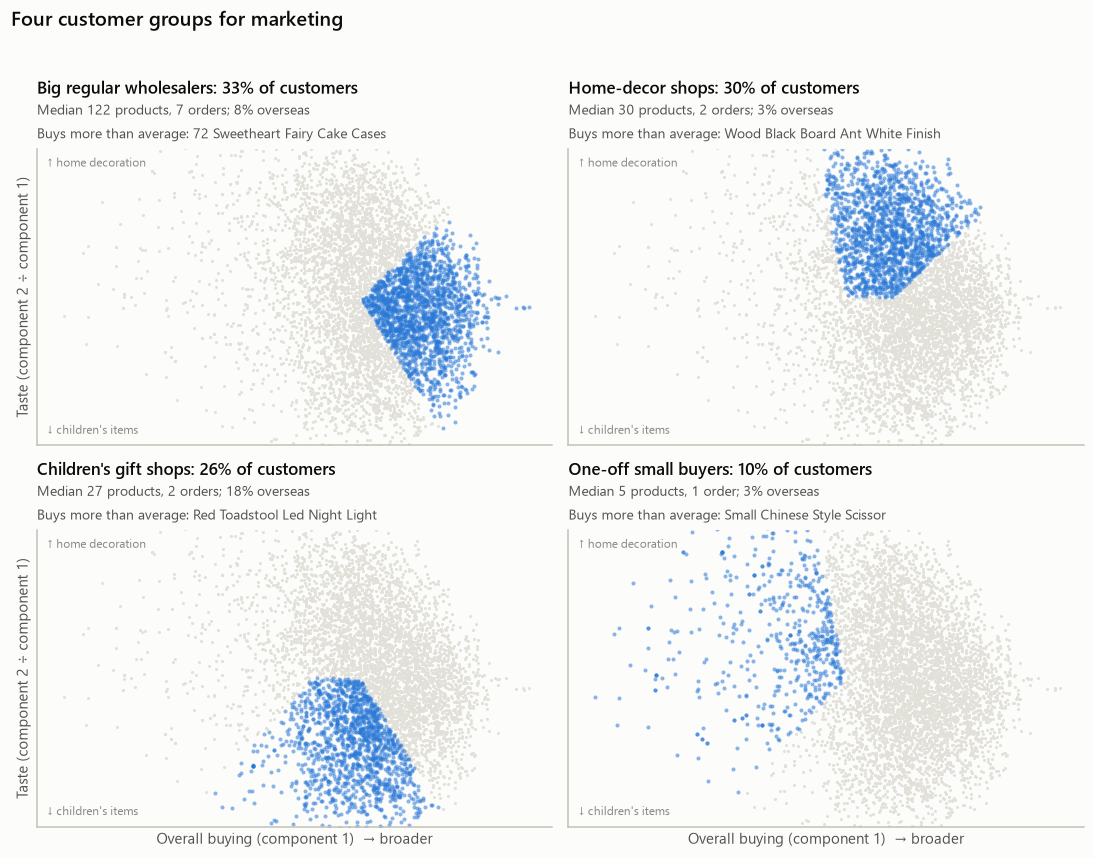

In [27]:
def first_fitting(items, width=62):
    # As many product names as fit on one subtitle line
    text = items[0]
    for item in items[1:]:
        if len(text) + len(item) + 2 > width:
            break
        text += ", " + item
    return text


lo, hi = np.percentile(taste, [1, 99])
fig, axes = plt.subplots(2, 2, figsize=(10, 7.6), sharex=True, sharey=True)
for ax, (g, p) in zip(axes.ravel(), profiles.iterrows()):
    member = labels == g
    ax.scatter(size[~member], taste[~member], s=4, color=GRID, linewidths=0)
    ax.scatter(size[member], taste[member], s=7, color=SLOTS[0], alpha=0.55, linewidths=0)
    orders = f"{p['median orders']:.0f} order{'' if p['median orders'] == 1 else 's'}"
    ax.set_title(f"{p['segment']}: {p['share']:.0%} of customers", pad=36)
    ax.text(0, 1.115, f"Median {p['median products']:.0f} products, {orders}; {p['overseas']:.0%} overseas",
            transform=ax.transAxes, color=INK_2, fontsize=9)
    ax.text(0, 1.035, "Buys more than average: " + first_fitting(p["distinctive products"], 40),
            transform=ax.transAxes, color=INK_2, fontsize=9)
    ax.set_xscale("log")
    ax.set_ylim(lo, hi)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.minorticks_off()
    ax.grid(False)
    ax.text(0.02, 0.97, "↑ home decoration", transform=ax.transAxes, fontsize=8, color=MUTED, va="top")
    ax.text(0.02, 0.03, "↓ children's items", transform=ax.transAxes, fontsize=8, color=MUTED, va="bottom")
for ax in axes[1]:
    ax.set_xlabel("Overall buying (component 1)  → broader")
for ax in axes[:, 0]:
    ax.set_ylabel("Taste (component 2 ÷ component 1)")
fig.suptitle("Four customer groups for marketing", x=0.01, ha="left", y=1.02, fontsize=13, fontweight="semibold")
fig.tight_layout()
fig.savefig(FIGURES / "customer_map.png")
plt.show()

## 7. ML7: does the purchase value change the hit rate?

Yes, a lot. The validation sweep in section 2 already answers it. The table puts the three purchase
values side by side at the chosen k and scoring rule, with the test hit rate for reference. The
choice was made on validation, before the test numbers below were computed.

In [28]:
sensitivity = {}
for value, label in VALUES.items():
    A_v = rec.load(value)[0]
    model = rec.fit("svd", A_v, K)
    score = rec.similarity_scorer(model.components_.T) if COSINE_RULE else rec.reconstruction_scorer(model)
    test_rate = rec.hit_rate(rec.recommend(A_v, score, customers=test_customers), test_customers, holdout)
    val_rate = sweep.query("value == @value and k == @K and rule == @RULE")["hit_rate"].item()
    sensitivity[label] = {"validation hit rate": val_rate, "test hit rate": test_rate}
sensitivity = pd.DataFrame(sensitivity).T
sensitivity.map(pct)

,validation hit rate,test hit rate
log(1 + units),38.9%,37.6%
1/0 bought,42.4%,40.4%
units,23.6%,22.4%


Raw units do worst. A handful of bulk orders (cells of thousands of units) dominate SVD's squared
error, so the components describe wholesale volume instead of taste. log(1 + units) tames the tail.
A plain 1/0 "bought it" flag does best: for "what will this shop try next", *whether* a shop buys a
product carries more signal than *how many* it buys.

## 8. The success targets, checked

These are the targets from the README (J1), with the measured values. The numbers for the memo and
slides are written to [reports/results.md](reports/results.md) and `reports/results.json`.

In [29]:
sizes_ok = profiles["share"].min() >= 0.05
overlap_ok = options.loc[N_GROUPS, "most shared top-10 products"] <= 5
targets = pd.DataFrame([
    ("1. Shrink the data", "Stored factors at least 10x smaller than the full table",
     f"{factors_mb:.1f} MB against {dense_mb:.1f} MB: {dense_mb / factors_mb:.0f}x smaller", dense_mb / factors_mb >= 10),
    ("2. Runs nightly", "Whole nightly job under 1 minute", f"{job_seconds:.1f} s, peak {job_peak:.0f} MB", job_seconds < 60),
    ("3. Beats best sellers", "Hit rate at 10 at least 3 points above the baseline",
     f"{pct(model_hits.mean())} against {pct(base_hits.mean())}: {gain * 100:+.1f} points "
     f"(95% interval {low * 100:+.1f} to {high * 100:+.1f})", gain >= 0.03),
    ("4. Customer groups", "3 to 6 groups, each at least 5%, at most 5 shared top-10 products",
     f"{N_GROUPS} groups, smallest {profiles['share'].min():.0%}, at most "
     f"{options.loc[N_GROUPS, 'most shared top-10 products']:.0f} shared", 3 <= N_GROUPS <= 6 and sizes_ok and overlap_ok),
], columns=["Target", "Threshold", "Measured", "Met"])
targets["Met"] = targets["Met"].map({True: "Yes", False: "No"})
targets

,Target,Threshold,Measured,Met
0,1. Shrink the data,Stored factors at least 10x smaller than the f...,5.1 MB against 160.6 MB: 31x smaller,Yes
1,2. Runs nightly,Whole nightly job under 1 minute,"0.7 s, peak 327 MB",Yes
2,3. Beats best sellers,Hit rate at 10 at least 3 points above the bas...,40.4% against 26.9%: +13.5 points (95% interva...,Yes
3,4. Customer groups,"3 to 6 groups, each at least 5%, at most 5 sha...","4 groups, smallest 10%, at most 0 shared",Yes


In [30]:
numbers = {
    "model": {"method": "Truncated SVD", "value": VALUE, "value_label": VALUES[VALUE], "k": K, "rule": RULE},
    "validation": choice,
    "test": {"customers": int(len(test_customers)), "held_out_pairs": int(len(holdout)),
             "hit_rate": float(model_hits.mean()), "baseline": float(base_hits.mean()),
             "gain_points": float(gain * 100), "gain_interval_points": [float(low * 100), float(high * 100)],
             "cosine_rule_hit_rate": float(cosine_hits.mean())},
    "size": {"factors_mb": factors_mb, "dense_mb": dense_mb, "times_smaller": dense_mb / factors_mb,
             "relative_error": float(svd_loss["relative_error"]), "share_kept": float(svd_loss["share_kept"])},
    "job": {"seconds": job_seconds, "peak_mb": job_peak},
    "coverage": coverage,
    "pca": {"hit_rate": float(h.loc[REBUILT, "PCA"]), "variance_explained": float(pca_loss["share_kept"]),
            "dense_centring_peak_mb": dense_peak},
    "comparison": {
        **{m: {"fit_seconds": c["fit seconds"], "peak_mb": c["peak MB during fit"], "factors_mb": c["stored factors MB"],
               "relative_error": float(loss_m["relative_error"]), "hit_rate": float(h.loc[REBUILT, METHODS[m]])}
           for m, c, loss_m in [("svd", c_svd, svd_loss), ("pca", c_pca, pca_loss)]},
        "average_share": float(average_share), "list_overlap": float(overlap), "dense_centring_peak_mb": dense_peak},
    "also_bought_example": {"product": products["Description"].iloc[int(np.argmax(buyers))].title(),
                            "list": names(also_bought[int(np.argmax(buyers))])},
    "segments": [{"name": p["segment"], "share": p["share"], "median_products": p["median products"],
                  "median_orders": p["median orders"], "median_spend_gbp": p["median spend (GBP)"],
                  "overseas": p["overseas"], "top_overseas": p["top overseas countries"],
                  "distinctive": p["distinctive products"][:5]} for _, p in profiles.iterrows()],
    "sensitivity": {label: row.to_dict() for label, row in sensitivity.iterrows()},
}
(REPORTS / "results.json").write_text(json.dumps(numbers, indent=2, default=float), encoding="utf-8")

segment_rows = [{"Segment": p["segment"], "Customers": f"{p['share']:.0%}", "Median products": f"{p['median products']:.0f}",
                 "Median orders": f"{p['median orders']:.0f}", "Median spend": f"£{p['median spend (GBP)']:,.0f}",
                 "Overseas": f"{p['overseas']:.0%}", "Distinctive products": ", ".join(p["distinctive products"][:4])}
                for _, p in profiles.iterrows()]
results_md = f'''# Results (ML2 to ML7)

Generated by `analysis.ipynb`. Final model: Truncated SVD on the {VALUES[VALUE]} matrix, k = {K},
{RULE} scoring rule, all chosen on the validation split ([model_choice.json](model_choice.json)).

## Success targets

{md_table(targets)}

## ML2: choosing k

On the validation split ({len(val_customers):,} customers, best-seller baseline {pct(val_baseline)}), the
{RULE} rule on the {VALUES[VALUE]} matrix scored best: {pct(curve.max())} at k = {curve.idxmax()}. The smallest k
within 1 point of that is **k = {K}** ({pct(curve[K])}). The brief's cosine rule stayed below best sellers at
every k and purchase value. The relative reconstruction error at k = {K} is {svd_loss["relative_error"]:.3f}.

![Choosing k](../figures/choose_k.png)

## ML4: held-out test purchases

{md_table(results.reset_index().rename(columns={"index": "Recommender"}))}

{len(test_customers):,} test customers; model minus baseline {gain * 100:+.1f} points (95% bootstrap interval
{low * 100:+.1f} to {high * 100:+.1f}). The nightly job takes {job_seconds:.1f} s and stores
{factors_mb:.1f} MB of factors, against {dense_mb:.1f} MB for the full table.

{md_table(pd.Series(coverage).reset_index().rename(columns={"index": "Coverage check", 0: "Value"}))}

## ML6: customer groups

{md_table(segment_rows)}

![Customer map](../figures/customer_map.png)

## ML7: purchase value

{md_table(sensitivity.map(pct).reset_index().rename(columns={"index": "Purchase value"}))}
'''
(REPORTS / "results.md").write_text(results_md, encoding="utf-8")
print("wrote reports/results.md and reports/results.json")

wrote reports/results.md and reports/results.json
